# Halifax 311 agent demand: seasonality and source breaks

Agent demand is `HANDLED + ABANDONED` per half-hour, on local time after the time-base and duplicate repairs (`src/clean.py`). Run `uv run python -m src.clean` first.

In [1]:
import sys

sys.path.insert(0, "..")  # the repository root, for src

import matplotlib.pyplot as plt
import pandas as pd

from pathlib import Path

from src.clean import DUPLICATED, WINDOWS, local_time, window

s = pd.read_parquet("../data/processed/series.parquet")
raw = pd.read_parquet(sorted(Path("../data/raw").glob("call_volumes_*.parquet"))[-1])
raw["demand"] = raw.HANDLED + raw.ABANDONED
raw["local"] = local_time(raw)
plt.rcParams.update({"figure.figsize": (10, 3.5), "axes.spines.top": False, "axes.spines.right": False})

## Daily shape

Agents work 08:00–20:00 on weekdays and 09:00–17:30 at weekends. The weekday peak is 09:30–11:30. Shaded slots are open.

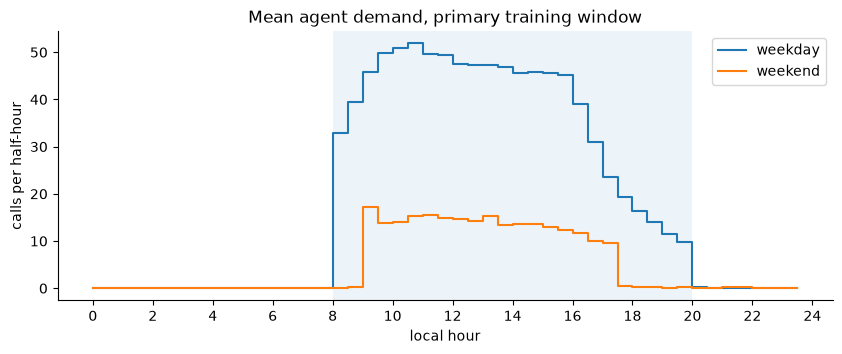

In [2]:
p = window(s, "primary")
p = p[p.day_kind == "normal"]
slot = p.index.hour + p.index.minute / 60
fig, ax = plt.subplots()
for name, mask in {"weekday": p.index.dayofweek < 5, "weekend": p.index.dayofweek >= 5}.items():
    ax.plot(p[mask].groupby(slot[mask]).demand.mean(), drawstyle="steps-post", label=name)
ax.axvspan(8, 20, alpha=0.08)
ax.set(xlabel="local hour", ylabel="calls per half-hour", title="Mean agent demand, primary training window", xticks=range(0, 25, 2))
ax.legend();

## Weekly shape

Monday to Wednesday carry the most calls. Demand falls on Thursday and Friday. Saturday carries about 30% of a weekday, and Sunday about 20%.

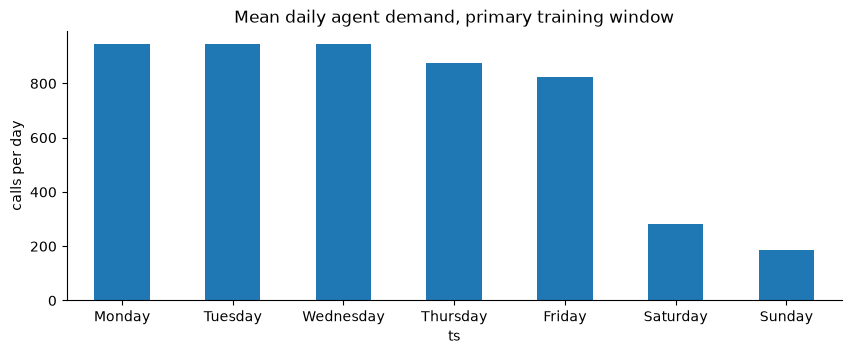

In [3]:
daily = p.demand.resample("D").sum()
daily = daily[daily > 0]
daily.groupby(daily.index.day_name()).mean().reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
).round().plot.bar(ylabel="calls per day", title="Mean daily agent demand, primary training window", rot=0);

## Year and source breaks

From 2023-05-23 to 2024-07-16 the source counts most days twice (shaded grey). After the repair the level is continuous. The dashed line at 2024-07-17 is the Enghouse cutover. The training windows and the test window are marked.

/var/folders/s9/306d5gf10_zb1v1h7_34vn380000gn/T/ipykernel_72372/385049851.py:1: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  end = WINDOWS["test"][1] + pd.Timedelta(hours=23)


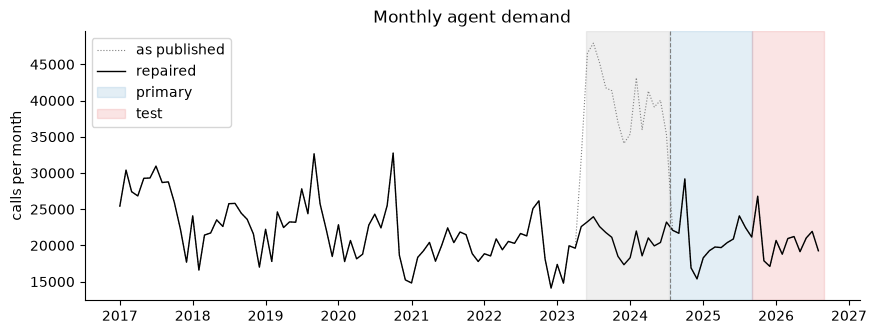

In [4]:
end = WINDOWS["test"][1] + pd.Timedelta(hours=23)
monthly = s.loc[:end].demand.resample("MS").sum()
published = raw[raw.local <= end].set_index("local").demand.resample("MS").sum()
fig, ax = plt.subplots()
ax.plot(published, color="grey", lw=0.8, ls=":", label="as published")
ax.plot(monthly, color="k", lw=1, label="repaired")
for name, colour in {"primary": "tab:blue", "test": "tab:red"}.items():
    a, b = WINDOWS[name]
    ax.axvspan(a, b, alpha=0.12, color=colour, label=name)
ax.axvspan(*DUPLICATED, alpha=0.12, color="grey")
ax.axvline(WINDOWS["primary"][0], ls="--", lw=0.8, color="grey")
ax.set(ylabel="calls per month", title="Monthly agent demand")
ax.legend(loc="upper left");

Before the Enghouse cutover, July to October are the busiest months, at 10–20% above the mean. December and February are the quietest, at 16–22% below. The primary window holds one annual cycle, so it cannot estimate this pattern.

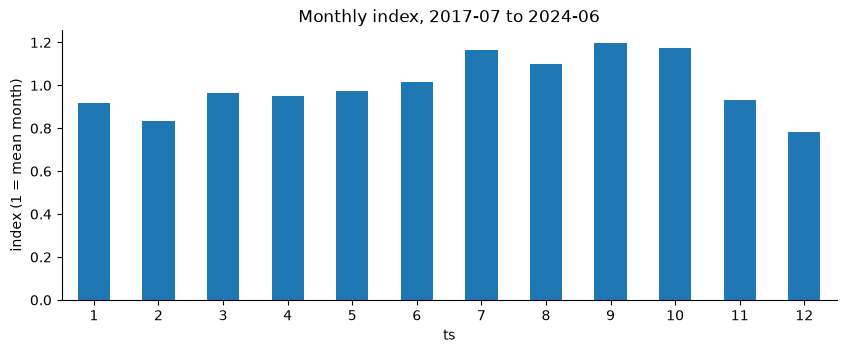

In [5]:
pre = window(s, "secondary")
pre = pre[pre.index < "2024-07-01"].demand.resample("MS").sum()
(pre.groupby(pre.index.month).mean() / pre.mean()).plot.bar(ylabel="index (1 = mean month)", title="Monthly index, 2017-07 to 2024-06", rot=0);

## Time-base repair

Before the repair, the labels from 2024-07-17 put the weekday peak in the late afternoon. After the repair, the profile matches the profile before 2023.

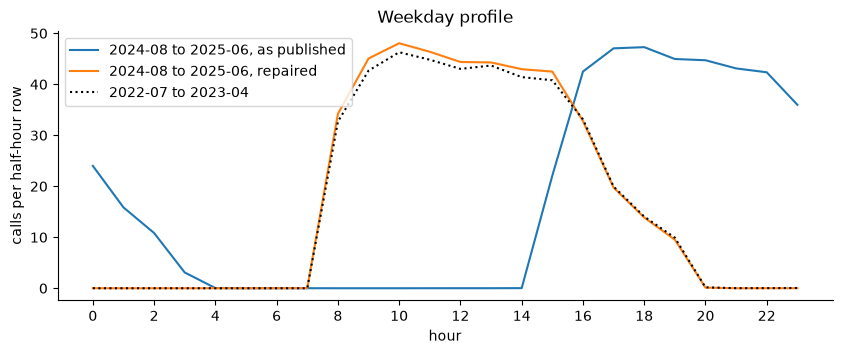

In [6]:
raw["label_hour"] = raw.MILITARY_HOUR
post = raw[(raw.local >= "2024-08-01") & (raw.local < "2025-07-01") & (raw.local.dt.dayofweek < 5)]
pre = raw[(raw.local >= "2022-07-01") & (raw.local < "2023-05-01") & (raw.local.dt.dayofweek < 5)]
fig, ax = plt.subplots()
ax.plot(post.groupby("label_hour").demand.mean(), label="2024-08 to 2025-06, as published")
ax.plot(post.groupby(post.local.dt.hour).demand.mean(), label="2024-08 to 2025-06, repaired")
ax.plot(pre.groupby(pre.local.dt.hour).demand.mean(), ls=":", color="k", label="2022-07 to 2023-04")
ax.set(xlabel="hour", ylabel="calls per half-hour row", title="Weekday profile", xticks=range(0, 24, 2))
ax.legend();

## Special days

`data/special_days.csv` lists closed days, named events, one outage and the two source transitions.

In [7]:
sd = pd.read_csv("../data/special_days.csv", parse_dates=["date"])
day = s.demand.resample("D").sum()
events = sd[sd.kind.isin(["event", "outage", "transition"])].assign(agent_calls=lambda d: day.reindex(d.date).to_numpy())
events

,date,kind,note,agent_calls
0,2017-07-01,event,Canada Day evening spike in calls offered,1110.0
1,2018-07-01,event,Canada Day evening spike in calls offered,418.0
2,2019-05-26,outage,Fewer than 24 intervals recorded,7.0
3,2019-07-01,event,Canada Day evening spike in calls offered,483.0
4,2019-09-07,event,Hurricane Dorian,1351.0
5,2019-09-08,event,Hurricane Dorian,1424.0
10,2022-09-24,event,Hurricane Fiona,721.0
11,2022-09-25,event,Hurricane Fiona,713.0
15,2023-05-23,transition,First day of duplicate counts,942.0
16,2023-05-29,event,Tantallon wildfire,2579.0
